# Nonlinear optimization

## Optimum power for a set of $m$ lamps illuminating a set of $n$ flat patches to best approach a target illumination

Consider $m$ lamps illuminating $n$ (small flat) patches. The illumination intensity $I_k$ at the $k$-th patch depends linearly on the lamp powers $p_j$ as:
$$
I_k = \sum\limits_{j=1}^m a_{k,j}p_j, \quad \text{with} \quad a_{k,j} = r^{-2}_{k,j}\max\{\cos(\theta_{k,j}, 0\},
$$
where $r_{k,j}$ is the length of the vector $\mathbf{r}_{k,j}$ connecting the center of the $k$-th patch to the position of the $m$-th lamp and $\theta_{k,j}$ is the angle between the patch normal vector $\mathbf{n}_{k}$ and $\mathbf{r}_{k,j}$. See the Convex Optimization book slides for more details.

The proposed problem is to achieve a desired illumination $I_{des}$ with bounded lamp powers ($p_{max}$), i.e.,
$$
\begin{align*}
    & \min. \underset{k=1, 2, \ldots, n}{\max}\vert \log(I_k) - \log(I_{des})\vert \\
    \text{s. t.}\quad & 0 \leq p_j \leq p_{max}, j = 1, 2, \ldots, m.
\end{align*}
$$


### Suboptimally solve the problem using according to the following approaches:

1. Using uniform power, i.e., $p_j = p, 0 \leq p \leq p_{max}$.
2. Using least-squares, i.e., $ \min. \sum\limits_{k=1}^n (I_k - I_{des})^2$, and rounding $p_j$ as $p_j = \max\{0, \min\{p_j, p_{max}\}\}$.
3. Using weighted least-squares, i.e., $ \min. \sum\limits_{k=1}^n (I_k - I_{des})^2 + \sum\limits_{j=1}^m w_j (p_j - p_{max}/2)^2$ and iteratively adjusting the weights $w_j$ until $0 \leq p \leq p_{max}, \forall j$.
4. Using linear programming, i.e.,
$$
\begin{align*}
    & \min. \underset{k=1, 2, \ldots, n}{\max}\vert I_k - I_{des}\vert \\
    \text{s. t.}\quad & 0 \leq p_j \leq p_{max}, j = 1, 2, \ldots, m.
\end{align*}
$$

### Solve the problem optimally using convex optimization

For this goal, consider the equivalent convex problem
$$
\begin{align*}
    & \min. \underset{k=1, 2, \ldots, n}{\max}h(I_k/I_{des}) \\
    \text{s. t.}\quad & 0 \leq p_j \leq p_{max}, j = 1, 2, \ldots, m,
\end{align*}
$$
where $h(u) = \max\{u, 1/u\}$.


# Scenario generation function

We begin the problem by creating the scenario with a certain number of patches (numPatches) and a certain amount of lamps (numLamps).

In [10]:
def generate_scenario(numLamps : int, numPatches : int):
    # Preallocate the patch and lamp positions
    patchPos = np.zeros((numPatches+1, 2), dtype=float)
    lampPos = np.zeros((numLamps, 2), dtype=float)

    # Generate patches extreme points
    x_patches = 1 + 3 * np.random.rand(numPatches+1)
    x_patches = np.cumsum(x_patches)
    y_patches = 2 + 1 * np.random.rand(numPatches+1)
    patchPos[:, 0] = x_patches
    patchPos[:, 1] = y_patches

    # Generate lamp extreme points
    # x_lamps = 1 + 5 * np.random.rand(numLamps)
    # x_lamps = np.cumsum(x_lamps)
    x_lamps = min(x_patches) + (max(x_patches) - min(x_patches)) * np.random.rand(numLamps)
    y_lamps = 6 + 1 * np.random.rand(numLamps)
    lampPos[:, 0] = x_lamps
    lampPos[:, 1] = y_lamps

    # return
    return patchPos, lampPos

We implement the objective function as

In [11]:
def objective_function(A : np.ndarray, p : np.ndarray, Ides : float)->float:
    '''
    objective_function(A : np.ndarray, p : np.ndarray, Ides : float)->float

    Description: Original objective function

    Input:
        A : matrix whose element [A]_{k,j} represents the coefficient related to
            the k-th patch and the j-th lamp
        p : vector whose j-th element [p]_j represents the power of the j-th lamp
        Ides: scalar that represents the desired illumination intensity

    Output:
        return the objective function of the main optimization problem
    '''
    return np.max(np.abs(np.log10(A @ p) - np.log10(Ides)))

# Set simulation parameters and generate scenario in a figure

Now we set the simulation parameters and create a representation of the scenario

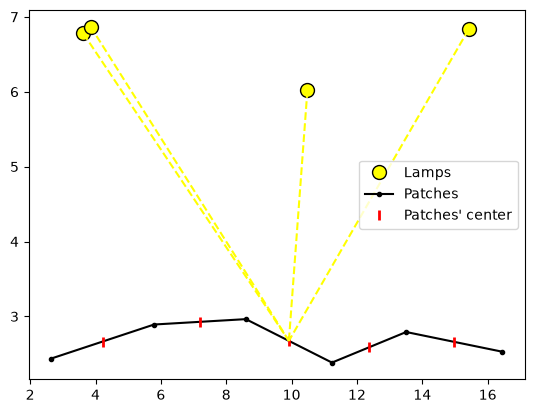

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp

# Seed
np.random.seed(0)

'''Simulation parameters'''
showFig = True;          # Figure
numLamps = 4;           # Number of lamps 4
numPatches = 5;         # Number of patches 5
maxPwr = 1;              # Maximum power [W]
desiredillum = 0.01;     # Desired illumination

# Position of the lamps and the extreme points of the patches in real matrices
# We assume that the lamps will be higher than the patches
# lampPos = np.array([[0.6838, 7.8976], [3.1835, 7.0690], [5.5327, 6.6806], [6.1963, 6.5203]])
# patchPos = np.array([[0.0762, 2.8621], [1.4506, 2.8733], [2.5122, 2.5864], [4.2246, 3.5846], [5.3512, 2.1960], [6.3013, 2.9838]])
patchPos, lampPos = generate_scenario(numLamps, numPatches)

# Position of the lamps and the extreme points of the patches in complex vectors
lampPos = lampPos[:, 0] + 1j * lampPos[:, 1]
patchPos = patchPos[:, 0] + 1j * patchPos[:, 1]

# Get the center of each patch
patchCenter = (patchPos[0:-1] + patchPos[1:]) / 2

# Obtain the normal versors to the patches
patch_diff_vector = patchPos[1:]-patchPos[0:-1]
normal_vectors = -np.imag(patch_diff_vector) + 1j * np.real(patch_diff_vector)
normal_versors = normal_vectors / np.abs(normal_vectors)    # Note that each vector is represented by a complex number

# Obtain the distance "vectors" represented by a complex number
mt_coeff = np.zeros((len(patchCenter), len(lampPos)), float)
for c1 in range(len(patchCenter)):
    for c2 in range(len(lampPos)):
        dist_vector = lampPos[c2] - patchCenter[c1]
        # We assume lamps in higher positions than patches
        ang = np.real(dist_vector * np.conjugate(normal_versors[c1])) / np.abs(dist_vector)
        mt_coeff[c1, c2] = (np.abs(dist_vector)**(-2)) * max(ang, 0)

''' Plot of the scenario '''
if showFig:
    # Plot the lamps
    plt.plot(np.real(lampPos), np.imag(lampPos), 'o', color="yellow", markersize = 10, markeredgecolor = 'k', label = "Lamps")

    # Plot the patches
    plt.plot(np.real(patchPos), np.imag(patchPos), 'o-', color = 'k', markersize = 3, label = "Patches")

    # Plot the center of the patches
    plt.plot(np.real(patchCenter), np.imag(patchCenter), '|', color = 'r', markersize = 7, markeredgewidth=2, label = "Patches' center")

    # Plot the lamps rays to a certain patch
    for c1 in range(len(lampPos)):
        plt.plot([np.real(lampPos[c1]), np.real(patchCenter[2])], [np.imag(lampPos[c1]), np.imag(patchCenter[2])], '--', color = "yellow")

    plt.legend()
    plt.show

# 1) Uniform power solution
Since the $m$-th lamp power $p_m$ must satisfy the power constraint $0 \leq p_m \leq p_{\text{max}}$, we design the uniform power solution $p_m = p_{\text{uni}}$ for every $m \in \{1, 2, \cdots, M\}$, where $0 \leq p_{\text{uni}} \leq p_{\text{max}}$. This means that this approach does not care to minimize the objective function, but only satisfies the set of possible solutions, which is the feasible set of the optimization problem. 

Let $f(\mathbf{p}) = \underset{k=1, 2, \ldots, n}{\max}\vert \log(I_k) - \log(I_{des})\vert$ be the true optimization function and let  $\mathbf{p} = p_{\text{uni}} \mathbf{1}_{M}$. The idea is to begin $p_{\text{uni}}$ with an initial real positive number greater than $0$ and less than $p_{\text{max}}$, and store in some data structure the result obtained when we apply the powers to $f(\mathbf{p})$. Then, we increase slightly $p_{\text{uni}}$ and store the new value. After we increase $p_{\text{uni}}$ until reach $p_{\text{max}}$, we compare the stored obtained values and get the $p_{\text{uni}}$ that minimized more the objective function.

In [13]:
def uniform_power(numLamps, maxPwr, mt_coeff, desiredillum):

    # Generate powers
    vt_powers = np.arange(1e-6, maxPwr, 0.001)

    # Objective values stored in a vector
    vt_obj = np.zeros((len(vt_powers),), dtype=float)

    # Store the last value
    store_last_obj_function_value = np.inf

    # Iterate over the powers
    for k in range(len(vt_powers)):

        # Create the lamp power vector
        p = vt_powers[k] * np.ones(numLamps)

        # Compute the objective value
        vt_obj[k] = objective_function(mt_coeff, p, desiredillum)

        # # If the current objective function is greater than the last value,
        # # we can stop the loop here, because we know (via inspection in a plot)
        # # that the stored objective values has one minimum. Then, if the nest
        # # value is greater than the past,this means that last value is the
        # # minimum
        # if store_last_obj_function_value >= vt_obj[k]:
        #     store_last_obj_function_value = vt_obj[k]
        # else:
        #     idx = k - 1
        #     break

    # Get the index of the minimum objective value
    idx = np.argmin(vt_obj)

    # The optimization variable is then
    p_uniform = vt_powers[idx] * np.ones(numLamps)

    # Return
    return p_uniform, vt_obj[idx], vt_obj

Now with the data and the functions, we find the uniform power solution and we show a plot representing relation $f(p_{\text{uni}} \mathbf{1}_M) \times p_{\text{uni}}$.

The solution p: [0.103001 0.103001 0.103001 0.103001]
The objective value obtained: 0.09978938524763858


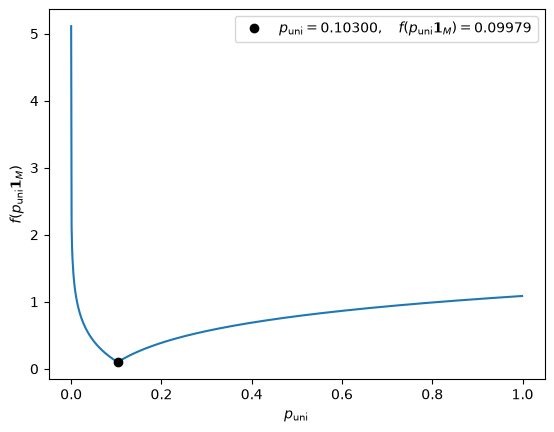

In [14]:
# Uniform power solution
power_uniform, obj_uniform_power, vt = uniform_power(numLamps, maxPwr, mt_coeff, desiredillum)
print("The solution p:", power_uniform)
print("The objective value obtained:", obj_uniform_power)

# f-string marking the solution point for the uniform power solution
s = (
    f'$p_{{\\text{{uni}}}} = {power_uniform[0]:.5f},'
    f'\\quad f(p_{{\\text{{uni}}}} \\mathbf{{1}}_M) = {obj_uniform_power:.5f}$'
)

plt.plot(np.arange(1e-6, maxPwr, 0.001), vt, '-')
plt.plot(power_uniform[0], obj_uniform_power, 'ko', label=s)
plt.legend()
plt.xlabel('$p_{\\text{uni}}$')
plt.ylabel('$f(p_{\\text{uni}} \\mathbf{1}_M)$')
plt.show()

# 2 Least squares
## 2.1 Least squares with a heuristic to the range of the lamps' powers
The least squares approach help us to minimize the variance of the illumination intensity of the lamps with respect to the desired illumination. That is why we would like to minimize $ \sum\limits_{k=1}^n (I_k - I_{des})^2$. Notice, however, that this approach does not include the constraint related to the range of the powers. So, one way to solve this issue is to force $p_j \in [0, p_{\text{max}}]$, and this is basically written as p_j = $\max\{0, \min\{p_j, p_{max}\}\}$. So, when $p_j > p_{\text{max}}$, we let $p_j = p_{\text{max}}$, and when $p_j < 0$, we say that $p_j = 0$.

Now we need to reformulate the least squares objective function, so we can get a more appropriate formulation. Notice that we can think $I_k$ as the $k$-th element of the vector $\mathbf{A}\mathbf{p}$, where, $\mathbf{A} \in \mathbb{R}^{n \times m}$ and $[\mathbf{A}]_{k,j} = a_{k,j}$. Then,
\begin{align}
\left[I_1 - I_{des}, \, I_2 - I_{des}, \, \cdots, \, I_n - I_{des} \right] &= \left[I_1, \, I_2, \, \cdots, \, I_n \right] - I_{des} \mathbf{1}, \\
&= \mathbf{A}\mathbf{p} - I_{des} \mathbf{1}
\end{align}
Thus, we rewrite:
\begin{align}
\sum\limits_{k=1}^n (I_k - I_{des})^2 &= \lVert \mathbf{A}\mathbf{p} - I_{des} \mathbf{1} \rVert_{2}^{2}.
\end{align}
The exact or the approximate solution that minimizes the objective function is  $\mathbf{p} = I_{des} \mathbf{A}^{\dagger} \mathbf{1}$. Note that we do not know if $[\mathbf{p}]_k$ is non-negative or is bounded by $p_{\text{max}}$. So, we adjust the solution, so we can have  a feasible solution to the optimization problem. Then, $p_k =\max\{0, \min\{[I_{des} \mathbf{A}^{\dagger} \mathbf{1}]_k, p_{max}\}\}$, for every $k$-th lamp.

In [15]:
# Solution with filtering steps to satisfy the feasibility conditions
power_least_squares = desiredillum * np.linalg.pinv(mt_coeff) @ np.ones(numPatches)
power_least_squares[power_least_squares > maxPwr] = maxPwr
power_least_squares[power_least_squares < 0] = 0
obj_least_squares = objective_function(mt_coeff, power_least_squares, desiredillum)

print("The solution p:", power_least_squares)
print("The objective value obtained:", obj_least_squares)

The solution p: [0.06936518 0.14902804 0.         0.94273485]
The objective value obtained: 0.7283916547531974


## 2.2 Quadratic programming
Notice that the least squares objetive function is a quadratic function with respect to the vector of the lamps' power $\mathbf{p} \in \mathbb{R}^{m}$. The last approach is kind of easy because it has a closed-form solution. Although, the price to pay, is that we needed to filter the solution, to obtain a feasible solution. Now, with quadratic programming, this is not an issue anymore, because we can include the linear constraints $0 \leq p_j \leq p_{\text{max}}, \, j \in \{1,2, \cdots, m\}$ which are linear. Using cvxpy, the solution can be easily obtained.

In [16]:
# Define the optimization variable
x = cp.Variable(numLamps)

# Define the objective function
objective = cp.sum_squares(mt_coeff @ x - desiredillum * np.ones(numPatches))

# Non-negativity contraints
constraint_lower_bound = [x >= 0]

# Maximum power contraints
constraint_upper_bound = [x <= maxPwr]

# Mesh the constraints
constraints = constraint_lower_bound
constraints += constraint_upper_bound

# Define the optimization problem
prob = cp.Problem(cp.Minimize(objective), constraints)

# Solve the optimization problem
prob.solve()

# Get the solution and transform to a np.ndarray
power_least_squares_cvxpy = np.array(x.value)

# Get the result of the original objective with the obtained solution
obj_least_squares_cvxpy = objective_function(mt_coeff, power_least_squares_cvxpy, desiredillum)

print("The solution p:", power_least_squares_cvxpy)
print("The objective value obtained:", obj_least_squares_cvxpy)

The solution p: [ 8.07952165e-02  1.46256021e-01 -3.70871866e-21  1.77504892e-01]
The objective value obtained: 0.06926720856303348
